<a href="https://colab.research.google.com/github/Fdau0002/Permanent-Magnet-Temperature-Estimate/blob/chore%2Fkaggle-dataset-integration/Permanent_Magnet_Temperature_Estimation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Engineering Interpretation

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("wkirgsn/electric-motor-temperature")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'electric-motor-temperature' dataset.
Path to dataset files: /kaggle/input/electric-motor-temperature


## 2.1 Dataset Description & Source

The dataset used in this investigation is the PMSM Electric Motor Temperature Measurement dataset, obtained from Kaggle and associated with Kirchgässner et al. (2021), Data-Driven Permanent Magnet Temperature Estimation in Synchronous Motors With Supervised Machine Learning: A Benchmark. The dataset contains measurements collected from a permanent magnet synchronous motor (PMSM) test bench operating at a sampling frequency of 2 Hz, corresponding to one observation every 0.5 seconds. The downloaded dataset contains 1,330,816 observations, 13 columns and 69 measurement profiles, representing approximately 184.84 hours of recorded motor operation. This is an expanded version of the dataset used in the original paper, which reported approximately 139 hours of measurements. Consequently, the published results will be used as reference benchmarks rather than targets for exact numerical reproduction.


In [2]:
import pandas as pd
import os

# Locate the CSV file downloaded by KaggleHub
csv_path = os.path.join(path, "measures_v2.csv")

print("File location:", os.path.abspath(csv_path))
print("File size (MB):", os.path.getsize(csv_path) / 1e6)

df = pd.read_csv(csv_path)

print("Observations:", len(df))
print("Columns:", len(df.columns))
print("Unique profiles:", df["profile_id"].nunique())
print("Recording hours:", len(df) / (2 * 3600))

File location: /kaggle/input/electric-motor-temperature/measures_v2.csv
File size (MB): 300.061411
Observations: 1330816
Columns: 13
Unique profiles: 69
Recording hours: 184.83555555555554


## 2.2 Inputs & Outputs

Each observation contains measurements of the motor's electrical, mechanical and thermal operating conditions. The dataset includes variables such as motor speed, torque, electrical currents, voltages, coolant temperature and ambient temperature, alongside several measured component temperatures. The primary prediction target is the permanent-magnet temperature, represented by the pm column.

The intended computational output is an estimated magnet temperature PM obtained using supervised machine-learning regression. The profile_id column identifies individual motor-recording sessions and is used for data partitioning rather than as a predictive input. The final model input set will be defined using the relevant measured and derived variables described in Table I of Kirchgässner et al. (2021). Temporal features based on exponentially weighted moving averages (EWMA) and standard deviations (EWMS) will subsequently be introduced.


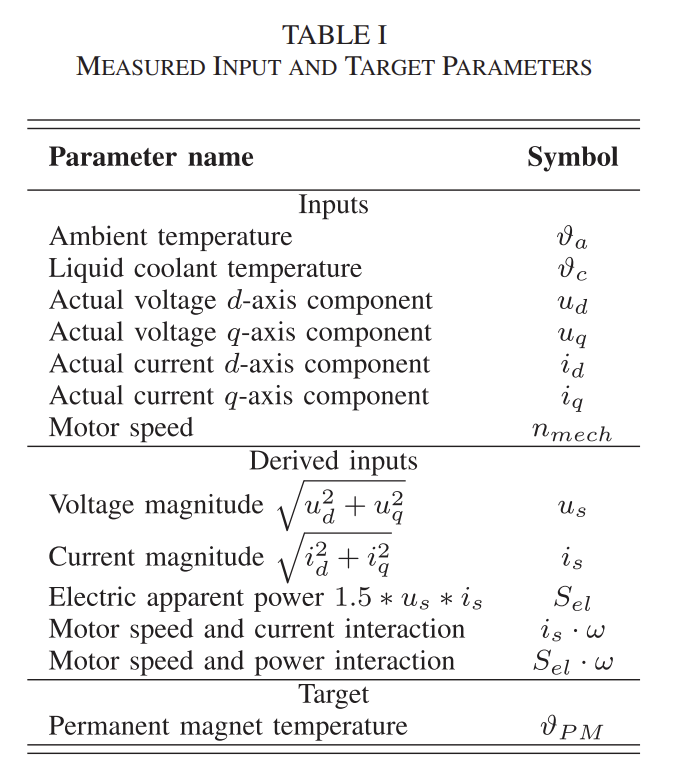

In [3]:
profile_summary = (
    df.groupby("profile_id")
    .agg(
        observations=("pm", "size"),
        pm_min=("pm", "min"),
        pm_max=("pm", "max")
    )
    .reset_index()
)

profile_summary["duration_hours"] = (
    profile_summary["observations"] / (2 * 3600)
)

display(profile_summary)

,profile_id,observations,pm_min,pm_max,duration_hours
0,2,19357,22.970417,45.985561,2.688472
1,3,19248,22.751144,29.011612,2.673333
2,4,33424,22.924950,99.396629,4.642222
3,5,14788,25.889381,39.938965,2.053889
4,6,40388,24.349821,93.512962,5.609444
...,...,...,...,...,...
64,76,22188,31.433067,82.554532,3.081667
65,78,8445,21.266710,68.029359,1.172917
66,79,31154,25.551253,97.153271,4.326944
67,80,23824,23.271483,81.760593,3.308889


## 2.3 Data Quality Assesment
Initial data inspection was conducted using Python and Pandas in Google Colab. The number of observations, available variables, recording profiles and temperature ranges were examined. The following checks were performed:

- **Missing values:** No missing values were identified across the 13 columns.
- **Duplicate observations:** No fully duplicated rows were identified.
- **Profile continuity:** All 69 measurement profiles appeared as individual continuous blocks within the dataset.
- **Recording duration:** Profile durations were estimated using the documented 2 Hz sampling frequency.
- **Temperature coverage:** Individual profiles exhibited different minimum and maximum permanent-magnet temperatures.



In [4]:
# Identify consecutive blocks of profile IDs
blocks = df["profile_id"].ne(
    df["profile_id"].shift()
).cumsum()

# Count distinct continuous blocks
n_blocks = blocks.nunique()
n_profiles = df["profile_id"].nunique()

print("Measurement profiles:", n_profiles)
print("Continuous blocks:", n_blocks)

if n_blocks == n_profiles:
    print("PASS: Each profile appears in one continuous block.")
else:
    print("CHECK: Some profiles may appear in multiple blocks.")

# Check missing values and duplicate rows
print("\nMissing values:")
print(df.isna().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Measurement profiles: 69
Continuous blocks: 69
PASS: Each profile appears in one continuous block.

Missing values:
u_q               0
coolant           0
stator_winding    0
u_d               0
stator_tooth      0
motor_speed       0
i_d               0
i_q               0
pm                0
stator_yoke       0
ambient           0
torque            0
profile_id        0
dtype: int64

Duplicate rows:
0


These results indicate that the dataset is suitable for further preprocessing and supervised regression modelling. However, the preliminary checks do not establish that all measurements are physically plausible or free from sensor errors. Since the dataset does not contain an explicit timestamp column, elapsed time within each profile can be reconstructed from sample position and the documented sampling interval, provided the original ordering is preserved.

## 2.4 Data Splitting Method
An initial 80/20 row-based partition was investigated. However, this approach divided recording profile 65 between the development and final test sets, meaning that observations from the same continuous motor-testing session appeared in both partitions.This was considered inappropriate for the intended evaluation objective: determining whether the estimator can generalise to previously unseen motor operating sessions.


In [5]:
cutoff = int(len(df) * 0.80)

train = df.iloc[:cutoff]
test = df.iloc[cutoff:]

shared_profiles = (
    set(train["profile_id"])
    & set(test["profile_id"])
)

print("Training rows:", len(train))
print("Testing rows:", len(test))
print("Profiles appearing in both:", shared_profiles)

Training rows: 1064652
Testing rows: 266164
Profiles appearing in both: {65}


Consequently, a profile-grouped partitioning strategy was adopted, following the grouping principle applied by Kirchgässner et al. (2021).To maintain temperature-condition coverage, profiles were divided into three groups according to their maximum recorded permanent-magnet temperature. A stratified split was then performed using a fixed random seed of 42.


In [6]:

import pandas as pd
from sklearn.model_selection import train_test_split

# STEP 4A: Summarise each measurement profile
profile_table = (
    df.groupby("profile_id")
    .agg(
        observations=("pm", "size"),
        pm_min=("pm", "min"),
        pm_max=("pm", "max"),
        pm_mean=("pm", "mean")
    )
    .reset_index()
    .sort_values("profile_id")
    .reset_index(drop=True)
)

# STEP 4B: Stratify profiles by maximum PM temperature
# Three approximately equal-sized temperature groups
profile_table["temperature_group"] = pd.qcut(
    profile_table["pm_max"],
    q=3,
    labels=["Low", "Medium", "High"]
)

# STEP 4C: Split complete profiles, NOT individual rows
train_ids, test_ids = train_test_split(
    profile_table["profile_id"],
    test_size=0.20,
    random_state=42,
    stratify=profile_table["temperature_group"]
)

train_ids = sorted(train_ids.tolist())
test_ids = sorted(test_ids.tolist())

# STEP 4D: Create development and final test datasets
train_df = df[df["profile_id"].isin(train_ids)].copy()
test_df = df[df["profile_id"].isin(test_ids)].copy()

# STEP 4E: Verify no profile overlap
assert set(train_ids).isdisjoint(set(test_ids))
assert len(train_df) + len(test_df) == len(df)

print("Development profiles:", len(train_ids))
print("Test profiles:", len(test_ids))
print("Development observations:", len(train_df))
print("Test observations:", len(test_df))

print("\nActual proportions:")
print(f"Development: {len(train_df)/len(df)*100:.2f}%")
print(f"Final test:  {len(test_df)/len(df)*100:.2f}%")

print("\nFinal test profile IDs:", test_ids)
print("Profile overlap:", set(train_ids) & set(test_ids))



Development profiles: 55
Test profiles: 14
Development observations: 1055198
Test observations: 275618

Actual proportions:
Development: 79.29%
Final test:  20.71%

Final test profile IDs: [13, 16, 23, 24, 29, 42, 44, 47, 53, 56, 62, 67, 71, 78]
Profile overlap: set()


In [7]:

# Assign split labels to profiles
profile_table["split"] = profile_table["profile_id"].apply(
    lambda pid: "Test" if pid in test_ids else "Development"
)

# Count low/medium/high temperature profiles in each set
print("Temperature-group distribution:")
display(
    pd.crosstab(
        profile_table["split"],
        profile_table["temperature_group"]
    )
)

# Compare measurement coverage
for name, data in [("Development", train_df), ("Test", test_df)]:
    print(f"\n{name} set:")
    print("Profiles:", data["profile_id"].nunique())
    print("PM range (°C):", data["pm"].min(), "to", data["pm"].max())
    print("Motor speed range:", data["motor_speed"].min(),
          "to", data["motor_speed"].max())
    print("Torque range:", data["torque"].min(),
          "to", data["torque"].max())

# Save profile assignments for reproducibility
profile_table.to_csv("profile_split.csv", index=False)


Temperature-group distribution:


temperature_group,Low,Medium,High
split,,,
Development,18,18,19
Test,5,5,4



Development set:
Profiles: 55
PM range (°C): 20.856956481933597 to 109.33384704589844
Motor speed range: -275.54914411131955 to 6000.01513671875
Torque range: -246.0862033395314 to 261.0057067871094

Test set:
Profiles: 14
PM range (°C): 21.032411575317383 to 113.60662841796876
Motor speed range: -0.0191213488578796 to 5981.344042117183
Torque range: -246.46666318909087 to 260.83477783203125



| Property | Development Set | Final Test Set |
|:---|:---:|:---:|
| Measurement Profiles | 55 | 14 |
| Observations | 1,055,198 | 275,618 |
| Dataset Proportion | 79.29% | 20.71% |
| Recording Duration | 146.56 h | 38.28 h |
| Low-temperature profiles | 18 | 5 |
| Medium-temperature profiles | 18 | 5 |
| High-temperature profiles | 19 | 4 |

The absence of overlapping profile identifiers was verified programmatically. The achieved proportions differ slightly from the targeted 80/20 division because complete recording sessions were preserved. The approximately 20% test allocation was selected as a practical holdout size consistent with the evaluation approach demonstrated in the MMA3001 teaching material, while retaining sufficient development observations for model training and cross-validation. It is an adaptation rather than an exact reproduction of the original paper's seven-hour holdout.

The selected test profiles will remain excluded from model fitting and hyperparameter optimisation. Within the development set, stratified grouped three-fold cross-validation will be implemented for model selection and optimisation. The same profile assignments will subsequently be used to evaluate the effects of reducing the estimator's sampling frequency, ensuring consistent comparisons between the original and modified computational approaches.


## 2.5 Scope and Limitations
Initial data inspection was conducted using Python and Pandas in Google Colab. The number of observations, available variables, recording profiles and temperature ranges were examined. The following checks were performed:


# 3 Computational Solution



## 3.1 Temporal Feature Engineering

Following the methodology of Kirchgässner et al. (2021), exponentially weighted moving averages (EWMA) and exponentially weighted moving standard deviations (EWMS) were implemented to incorporate the historical behaviour of motor operating conditions into the machine-learning inputs.

This feature engineering is necessary because permanent-magnet temperature depends on both current and previous motor operation. Conventional regression models, including ordinary least squares (OLS), do not explicitly maintain a history of previous observations. EWMA and EWMS provide historical information through additional predictor variables.

The EWMA was calculated using:

$$
\mu_t = \frac{\sum_{i=0}^{t} w_i x_{t-i}}{\sum_{i=0}^{t} w_i}
$$

where the weighting factor and smoothing parameter are defined as:

$$
w_i = (1-\alpha)^i, \qquad \alpha = \frac{2}{s+1}
$$

Here, $x_t$ represents the sensor measurement at time $t$, $\alpha$ controls the weighting of historical observations, and $s$ represents the smoothing span.

Larger spans preserve the influence of older measurements for longer, while smaller spans respond more rapidly to changes in motor operating conditions.


In [10]:

import numpy as np
import pandas as pd

def make_paper_inputs(data):
    """Construct the 12 PMSM inputs from Table I of the paper."""

    X = pd.DataFrame(index=data.index)

    # Seven measured inputs
    X["theta_a"] = data["ambient"]
    X["theta_c"] = data["coolant"]
    X["u_d"] = data["u_d"]
    X["u_q"] = data["u_q"]
    X["i_d"] = data["i_d"]
    X["i_q"] = data["i_q"]
    X["n_mech"] = data["motor_speed"]

    # Five derived inputs
    X["u_s"] = np.hypot(X["u_d"], X["u_q"])
    X["i_s"] = np.hypot(X["i_d"], X["i_q"])

    # Apparent electrical power
    X["S_el"] = 1.5 * X["u_s"] * X["i_s"]

    # Angular speed in rad/s
    omega = 2 * np.pi * X["n_mech"] / 60

    X["i_s_omega"] = X["i_s"] * omega
    X["S_el_omega"] = X["S_el"] * omega

    return X



## 3.2 Python Implementation

The computational implementation was developed in Python using Pandas and NumPy.

First, twelve predictor variables were constructed from seven measured quantities and five derived quantities, following Table I of Kirchgässner et al. (2021).

A reusable function `make_temporal_features()` was then developed to generate EWMA and EWMS features for each predictor variable and smoothing span.

Four illustrative spans of 10, 50, 200 and 1,000 samples were initially selected to verify the implementation. These values were selected to demonstrate different smoothing timescales and do not represent optimised hyperparameters.

The resulting feature matrix consisted of:

| Feature category | Number |
|:-----------------|-------:|
| Original measured and derived predictors | 12 |
| EWMA features | 48 |
| EWMS features | 48 |
| **Total predictor variables** | **108** |


In [11]:

def make_temporal_features(X, profile_ids, spans):
    # Calculate temporal features independently per profile
    features = {}

    for column in X.columns:
        grouped = X[column].groupby(
            profile_ids, sort=False
        )

        for span in spans:
            features[f"{column}_ewma_s{span}"] = (
                grouped.transform(
                    lambda z: z.ewm(
                        span=span, adjust=True
                    ).mean()
                )
            )

            features[f"{column}_ewms_s{span}"] = (
                grouped.transform(
                    lambda z: z.ewm(
                        span=span, adjust=True
                    ).std(bias=True)
                )
            )

    return pd.concat(
        [X, pd.DataFrame(features, index=X.index)],
        axis=1
    )


In [13]:

# Test 1: Compare EWMA/EWMS against manual calculations

signal = np.array([10.0, 20.0, 30.0])
span = 3
alpha = 2 / (span + 1)

weights = (1 - alpha) ** np.arange(2, -1, -1)

manual_mean = np.sum(weights * signal) / weights.sum()

manual_std = np.sqrt(
    np.sum(weights * (signal - manual_mean)**2)
    / weights.sum()
)

pandas_ewm = pd.Series(signal).ewm(
    span=span, adjust=True
)

np.testing.assert_allclose(
    pandas_ewm.mean().iloc[-1], manual_mean
)

np.testing.assert_allclose(
    pandas_ewm.std(bias=True).iloc[-1],
    manual_std
)

print("PASS: EWMA/EWMS mathematical verification")
print("Manual EWMA:", manual_mean)
print("Manual EWMS:", manual_std)


# Test 2: Check that memory resets between profiles

toy_X = pd.DataFrame({
    "sensor": [10., 20., 30., 100., 100.]
})

toy_ids = pd.Series([1, 1, 1, 2, 2])

toy_features = make_temporal_features(
    toy_X, toy_ids, spans=[3]
)

assert toy_features.loc[3, "sensor_ewma_s3"] == 100.
assert toy_features.loc[3, "sensor_ewms_s3"] == 0.

print("PASS: Profile memory reset")


# Test 3: Verify that future values do not affect past features

modified_X = toy_X.copy()
modified_X.loc[2, "sensor"] = 100000.

modified_features = make_temporal_features(
    modified_X, toy_ids, spans=[3]
)

np.testing.assert_allclose(
    toy_features.loc[:1, "sensor_ewma_s3"],
    modified_features.loc[:1, "sensor_ewma_s3"]
)

print("PASS: No future-data leakage")


PASS: EWMA/EWMS mathematical verification
Manual EWMA: 24.285714285714285
Manual EWMS: 7.2843135908468355
PASS: Profile memory reset
PASS: No future-data leakage



## 3.3 Numerical and Real-Data Verification

Verification was performed before proceeding to machine-learning model training.

Initially, EWMA and EWMS calculations were compared against manually evaluated results using a synthetic signal of (10, 20, 30) and a smoothing span of 3. The manually calculated values agreed with the Pandas implementation within numerical tolerance.

Additional tests confirmed that temporal memory restarted at profile boundaries and that changing a future observation did not affect earlier EWMA results.

The implementation was subsequently tested using actual PMSM measurements. The first 300 observations from each of two development profiles (IDs 2 and 3) were selected, representing 600 observations across two independent sessions.

Four illustrative spans were applied to each of the twelve predictors, generating the expected 108-feature matrix.

**Table X. Real-data feature-engineering verification results.**

| Verification criterion | Result |
|:-----------------------|:-------|
| Measurement profiles | 2 |
| Observations | 600 |
| Original predictor variables | 12 |
| Generated predictor variables | 108 |
| Missing feature values | 0 |
| Non-finite feature values | 0 |
| Feature-dimension verification | Passed |
| Profile-initialisation verification | Passed |

The results confirmed that the feature-engineering pipeline produced the expected dimensions and numerically valid outputs for the selected real-data samples.

In [14]:

# Select two development profiles only
demo_ids = train_ids[:2]

demo_df = (
    train_df[train_df["profile_id"].isin(demo_ids)]
    .groupby("profile_id", sort=False)
    .head(300)
    .copy()
)

# Construct the twelve input variables
X_demo = make_paper_inputs(demo_df)

# Illustrative spans (NOT yet optimised)
example_spans = [10, 50, 200, 1000]

# Generate temporal features
X_temporal = make_temporal_features(
    X_demo,
    demo_df["profile_id"],
    spans=example_spans
)

# Verify feature matrix
assert X_temporal.shape[1] == 108
assert X_temporal.isna().sum().sum() == 0
assert np.isfinite(X_temporal.to_numpy()).all()

print("Profiles:", demo_df["profile_id"].nunique())
print("Original inputs:", X_demo.shape[1])
print("Total features:", X_temporal.shape[1])
print("Missing values:", X_temporal.isna().sum().sum())

display(X_temporal.iloc[:5, :16])


Profiles: 2
Original inputs: 12
Total features: 108
Missing values: 0


,theta_a,theta_c,u_d,u_q,i_d,i_q,n_mech,u_s,i_s,S_el,i_s_omega,S_el_omega,theta_a_ewma_s10,theta_a_ewms_s10,theta_a_ewma_s50,theta_a_ewms_s50
90975,19.995035,15.717488,0.051183,4.921712,-0.000385,0.000221,99.964539,4.921979,0.000444,0.003276,0.004645,0.034295,19.995035,0.000000,19.995035,0.000000
90976,19.954098,15.890841,0.074807,4.948537,-0.002003,0.000886,100.017822,4.949102,0.002191,0.016263,0.022945,0.170339,19.972520,0.020366,19.974157,0.020465
90977,19.924765,15.992567,0.063648,4.941477,0.000156,-0.000046,99.999977,4.941887,0.000163,0.001208,0.001706,0.012647,19.953322,0.028218,19.957030,0.028744
90978,19.903748,16.135164,0.076738,4.921178,0.001466,-0.001133,99.980309,4.921776,0.001853,0.013676,0.019396,0.143191,19.936990,0.032816,19.942900,0.034063
90979,19.888687,16.165384,0.084553,4.924347,0.000682,0.003452,100.023392,4.925073,0.003519,0.025997,0.036859,0.272299,19.923123,0.035288,19.931173,0.037517


## 3.4 Visual Verification of EWMA Behaviour

The implementation was further assessed by plotting the q-axis motor current against its exponentially weighted moving averages for measurement Profile 2.

Four illustrative spans of 10, 50, 200 and 1,000 samples were evaluated over the first 150 seconds of the recording.

The results demonstrated that smaller spans responded more rapidly to changes in the original current signal, whereas larger spans produced slower and more heavily smoothed responses.

Figure X. Raw q-axis current and corresponding EWMA responses for four smoothing spans in PMSM measurement Profile 2.

The observed behaviour was consistent with the expected mathematical characteristics of exponential smoothing and provided qualitative evidence supporting the implementation.

However, the numerical and visual verification results do not establish whether the selected temporal features improve permanent-magnet temperature prediction. Furthermore, the implementation uses a weighted standard deviation for EWMS, while Equation (4) of Kirchgässner et al. (2021) contains an ambiguity concerning the variance and standard-deviation convention.

The selection of optimal spans and the quantitative assessment of temperature-prediction accuracy will therefore be conducted during subsequent Bayesian optimisation and grouped cross-validation.

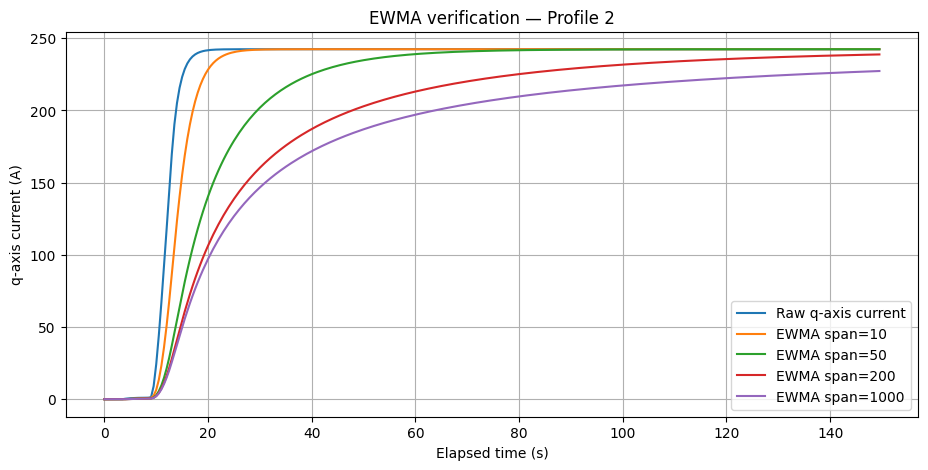

In [16]:

import matplotlib.pyplot as plt

# Examine one measurement profile
pid = demo_ids[0]

mask = demo_df["profile_id"] == pid
time = np.arange(mask.sum()) / 2  # Seconds at 2 Hz

plt.figure(figsize=(11, 5))

plt.plot(
    time,
    X_temporal.loc[mask, "i_q"].to_numpy(),
    label="Raw q-axis current"
)

for span in [10, 50, 200,1000]:
    plt.plot(
        time,
        X_temporal.loc[
            mask, f"i_q_ewma_s{span}"
        ].to_numpy(),
        label=f"EWMA span={span}"
    )

plt.xlabel("Elapsed time (s)")
plt.ylabel("q-axis current (A)")
plt.title(f"EWMA verification — Profile {pid}")
plt.legend()
plt.grid(True)
plt.show()


## 4. Implementation of Stratified Grouped 3-Fold Cross-Validation

## 4.1 Implementation of Stratified Grouped 3-Fold Cross-Validation
Following the feature-engineering verification, stratified grouped three-fold cross-validation was implemented to establish a consistent methodology for evaluating the regression models and their hyperparameters.

The previously established development/test partition was restored using the dataset downloaded through KaggleHub. The development partition consisted of 55 measurement profiles containing 1,055,198 observations, while the final test partition contained 14 profiles with 275,618 observations. The final test partition was reserved for subsequent model evaluation and excluded from cross-validation and hyperparameter optimisation.

A profile-level summary was constructed to calculate the number of observations and minimum and maximum permanent-magnet temperatures for each development profile. The profiles were then classified into three temperature groups: Low, Medium and High using the maximum recorded permanent-magnet temperature as the stratification criterion.

The StratifiedKFold method from Scikit-learn was applied to this profile-level summary using three folds, random shuffling and a fixed random seed of 42. This approach follows the principle of temperature-stratified profile-based validation adopted by Kirchgässner et al. (2021).

Importantly, the folds were constructed from complete measurement profiles rather than individual observations. This prevented measurements belonging to the same recording session from appearing simultaneously in the training and validation subsets of a given cross-validation iteration.

The implementation included assertions to verify the correct development/test partition sizes, complete fold assignment and absence of profile overlap. The resulting fold assignments were saved to profile_cv_assignments.csv for reproducibility.

In [19]:

import pandas as pd
from sklearn.model_selection import StratifiedKFold

# =====================================================
# STEP 6.1A — Restore the existing development/test split
# =====================================================

# df is already loaded from KaggleHub

test_ids = [
    13, 16, 23, 24, 29, 42, 44,
    47, 53, 56, 62, 67, 71, 78
]

train_df = df[
    ~df["profile_id"].isin(test_ids)
].copy()

test_df = df[
    df["profile_id"].isin(test_ids)
].copy()

# Verify the previously established partition
assert len(df) == 1330816
assert len(train_df) == 1055198
assert len(test_df) == 275618
assert set(train_df["profile_id"]).isdisjoint(
    set(test_df["profile_id"])
)

print("PASS: Development/test split restored")


# =====================================================
# STEP 6.1B — Summarise development profiles
# =====================================================

profile_cv = (
    train_df.groupby("profile_id")["pm"]
    .agg(
        observations="size",
        pm_min="min",
        pm_max="max"
    )
    .reset_index()
    .sort_values("profile_id")
    .reset_index(drop=True)
)

# Create three temperature categories based
# on each profile's maximum PM temperature
profile_cv["temperature_group"] = pd.qcut(
    profile_cv["pm_max"],
    q=3,
    labels=["Low", "Medium", "High"]
)


# =====================================================
# STEP 6.1C — Construct three stratified folds
# =====================================================

skf = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

profile_cv["cv_fold"] = -1

for fold, (_, val_indices) in enumerate(
    skf.split(
        profile_cv[["pm_max"]],
        profile_cv["temperature_group"]
    ),
    start=1
):
    profile_cv.loc[val_indices, "cv_fold"] = fold

print("PASS: Three validation folds created")


# =====================================================
# STEP 6.1D — Verify profile separation
# =====================================================

development_ids = set(profile_cv["profile_id"])

assert len(development_ids) == 55
assert profile_cv["cv_fold"].isin([1, 2, 3]).all()
assert development_ids.isdisjoint(set(test_ids))

for fold in [1, 2, 3]:

    val_ids = set(
        profile_cv.loc[
            profile_cv["cv_fold"] == fold,
            "profile_id"
        ]
    )

    fold_train_ids = development_ids - val_ids

    assert val_ids.isdisjoint(fold_train_ids)
    assert val_ids.isdisjoint(set(test_ids))

    print(f"\nFold {fold}")
    print("Training profiles:", len(fold_train_ids))
    print("Validation profiles:", len(val_ids))

print("\nPASS: No profile leakage detected")

# Save assignments for reproducibility
profile_cv.to_csv(
    "profile_cv_assignments.csv",
    index=False
)

print("Saved: profile_cv_assignments.csv")


PASS: Development/test split restored
PASS: Three validation folds created

Fold 1
Training profiles: 36
Validation profiles: 19

Fold 2
Training profiles: 37
Validation profiles: 18

Fold 3
Training profiles: 37
Validation profiles: 18

PASS: No profile leakage detected
Saved: profile_cv_assignments.csv


## 4.2 Verification of Cross-Validation Fold Distribution



The resulting cross-validation partitions were examined to verify their distribution across the three temperature groups and the total number of observations assigned to each fold.

**Table 4.1. Distribution of measurement profiles across temperature groups.**

| Validation fold | Low | Medium | High | Total profiles |
|:----------------|----:|-------:|-----:|---------------:|
| Fold 1 | 7 | 6 | 6 | 19 |
| Fold 2 | 6 | 5 | 7 | 18 |
| Fold 3 | 6 | 6 | 6 | 18 |
| **Total** | **19** | **17** | **19** | **55** |

The results demonstrate that each validation fold contained a reasonably balanced representation of the three maximum-temperature categories.

**Table 4.2. Validation-fold observation counts and recording durations.**

| Validation fold | Profiles | Observations | Duration (hours) |
|:----------------|---------:|-------------:|-----------------:|
| Fold 1 | 19 | 401,114 | 55.71 |
| Fold 2 | 18 | 362,087 | 50.29 |
| Fold 3 | 18 | 291,997 | 40.56 |
| **Total** | **55** | **1,055,198** | **146.56** |

Although the number of profiles was approximately balanced, the observation counts differed because individual recording sessions had different durations. This was retained to preserve complete profiles and prevent information leakage.

The verification assertions confirmed that all development observations were assigned to exactly one validation fold, with no overlap between training and validation profile IDs. The reserved final test profiles remained excluded.

During subsequent Bayesian optimisation, each proposed model configuration will be evaluated using all three folds. Its objective value will be the arithmetic mean of the three validation mean squared errors:

$$
\mathrm{MSE}_{\mathrm{CV}} = \frac{\mathrm{MSE}_1 + \mathrm{MSE}_2 + \mathrm{MSE}_3}{3}
$$

Using identical, fixed cross-validation assignments for all regression models ensures a consistent basis for comparing their proposed configurations.


In [20]:

# =====================================================
# STEP 6.1E — Verify temperature-group distribution
# =====================================================

print("Temperature-group distribution:")

display(
    pd.crosstab(
        profile_cv["cv_fold"],
        profile_cv["temperature_group"]
    )
)


# =====================================================
# STEP 6.1F — Verify fold sizes and coverage
# =====================================================

fold_summary = (
    profile_cv.groupby("cv_fold")
    .agg(
        profiles=("profile_id", "size"),
        observations=("observations", "sum"),
        min_pm=("pm_min", "min"),
        max_pm=("pm_max", "max")
    )
)

# The original dataset is sampled at 2 Hz
fold_summary["duration_hours"] = (
    fold_summary["observations"] / 7200
)

print("\nValidation-fold summary:")
display(fold_summary)

# Confirm that every development observation is assigned
assert fold_summary["observations"].sum() == len(train_df)
assert fold_summary["profiles"].sum() == 55

print("\nPASS: All development observations assigned")


Temperature-group distribution:


temperature_group,Low,Medium,High
cv_fold,,,
1,7,6,6
2,6,5,7
3,6,6,6



Validation-fold summary:


,profiles,observations,min_pm,max_pm,duration_hours
cv_fold,,,,,
1,19,401114,21.213623,109.333847,55.710278
2,18,362087,20.856956,105.948723,50.289861
3,18,291997,22.888792,99.396629,40.555139



PASS: All development observations assigned


## 4.3 Preliminary Verification of Regression Model Pipelines

Before conducting computationally expensive Bayesian optimisation, preliminary regression-training pipelines were implemented to verify compatibility between the engineered temporal features, the regression algorithms and the grouped validation methodology.

Six regression models investigated by Kirchgässner et al. (2021) were considered: Ordinary Least Squares (OLS), Support Vector Regression (SVR), k-Nearest Neighbours (k-NN), Random Forest, Extra Trees and Multi-Layer Perceptron (MLP).

In [21]:

import numpy as np
import pandas as pd

# =====================================================
# STEP 6.2A — Prepare a small development-data sample
# =====================================================

# These are example spans, not optimised values.
SMOKE_SPANS = [10, 50, 200, 1000]
SAMPLES_PER_PROFILE = 80

def make_pipeline_test_data(data, spans, samples_per_profile=80):
    """
    Create a small dataset to verify ML training pipelines.

    EWMA/EWMS is calculated using the full 2-Hz history
    of each profile before selecting training observations.
    """
    sampled_profiles = []

    for pid, profile in data.groupby(
        "profile_id", sort=False
    ):
        # Construct the 12 original input variables
        X = make_paper_inputs(profile)

        # Calculate temporal features from full history
        X_full = make_temporal_features(
            X, profile["profile_id"], spans
        )

        # Select representative positions across this profile
        n = min(samples_per_profile, len(profile))

        positions = np.linspace(
            0, len(profile) - 1, n, dtype=int
        )

        sample = X_full.iloc[positions].copy()

        # Target is stored separately from predictors
        sample["pm_target"] = (
            profile["pm"].iloc[positions].to_numpy()
        )
        sample["profile_id"] = pid

        sampled_profiles.append(sample)

    return pd.concat(
        sampled_profiles, ignore_index=True
    )


smoke_df = make_pipeline_test_data(
    train_df,
    SMOKE_SPANS,
    samples_per_profile=SAMPLES_PER_PROFILE
)

# Verification
assert smoke_df["profile_id"].nunique() == 55
assert len(smoke_df) == 55 * SAMPLES_PER_PROFILE
assert smoke_df.shape[1] == 110  # 108 + target + profile ID
assert smoke_df.isna().sum().sum() == 0
assert np.isfinite(smoke_df.to_numpy()).all()

print("PASS: Pipeline test dataset prepared")
print("Observations:", len(smoke_df))
print("Predictor features:", smoke_df.shape[1] - 2)
print("Profiles:", smoke_df["profile_id"].nunique())


PASS: Pipeline test dataset prepared
Observations: 4400
Predictor features: 108
Profiles: 55



### 4.3.1 Preparation of the Preliminary Training Dataset

The complete development dataset contained more than one million observations. To reduce computational requirements during initial implementation testing, a smaller dataset was constructed by selecting 80 observations distributed across each of the 55 development profiles.

Importantly, the EWMA/EWMS temporal features were calculated using each profile's complete original 2 Hz measurement history before selecting the observations. This ensured that the selected features retained information from the preceding measurements rather than being calculated from an artificially shortened history.

Four illustrative spans of 10, 50, 200 and 1,000 samples were used, consistent with the earlier feature-engineering verification. These were fixed demonstration settings, not optimised hyperparameters.

**Table 4.3. Preliminary regression dataset characteristics.**

| Characteristic | Result |
|:---------------|-------:|
| Development profiles represented | 55 |
| Selected observations per profile | 80 |
| Total observations | 4,400 |
| Predictor variables | 108 |
| Prediction target | Permanent-magnet temperature (`pm`) |
| Missing feature values | 0 |

The resulting dataset passed the dimensional and numerical-validity checks and was used exclusively for preliminary model-pipeline verification.


In [22]:

import time
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor
)
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# =====================================================
# STEP 6.2B — Select the first grouped CV fold
# =====================================================

val_ids = set(
    profile_cv.loc[
        profile_cv["cv_fold"] == 1,
        "profile_id"
    ]
)

train_sample = smoke_df[
    ~smoke_df["profile_id"].isin(val_ids)
].copy()

val_sample = smoke_df[
    smoke_df["profile_id"].isin(val_ids)
].copy()

# Separate inputs and target
feature_cols = [
    c for c in smoke_df.columns
    if c not in ["pm_target", "profile_id"]
]

X_train = train_sample[feature_cols]
y_train = train_sample["pm_target"]

X_val = val_sample[feature_cols]
y_val = val_sample["pm_target"]

# Verify no profile overlap
assert set(train_sample["profile_id"]).isdisjoint(
    set(val_sample["profile_id"])
)

assert len(feature_cols) == 108

print("Training profiles:",
      train_sample["profile_id"].nunique())
print("Validation profiles:",
      val_sample["profile_id"].nunique())


# =====================================================
# STEP 6.2C — Define the six regression models
# =====================================================

models = {
    "OLS": LinearRegression(),

    "SVR": SVR(
        kernel="rbf",
        C=1.0,
        epsilon=0.1
    ),

    "k-NN": KNeighborsRegressor(
        n_neighbors=10,
        weights="distance"
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=20,
        max_depth=12,
        random_state=42,
        n_jobs=2
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=20,
        max_depth=12,
        random_state=42,
        n_jobs=2
    ),

    "MLP": MLPRegressor(
        hidden_layer_sizes=(32,),
        max_iter=150,
        random_state=42
    )
}


# =====================================================
# STEP 6.2D — Train, predict and evaluate each model
# =====================================================

results = []

for name, estimator in models.items():

    # StandardScaler is fitted on TRAINING data only.
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", estimator)
    ])

    # Train
    start = time.perf_counter()
    pipeline.fit(X_train, y_train)
    training_time = time.perf_counter() - start

    # Predict on unseen validation profiles
    start = time.perf_counter()
    predictions = pipeline.predict(X_val)
    inference_time = time.perf_counter() - start

    # Calculate prediction errors
    errors = y_val.to_numpy() - predictions

    results.append({
        "Model": name,
        "MSE": mean_squared_error(y_val, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_val, predictions)),
        "MAE": mean_absolute_error(y_val, predictions),
        "R2": r2_score(y_val, predictions),
        "Max Error": np.max(np.abs(errors)),
        "Training Time (s)": training_time,
        "Inference Time (s)": inference_time
    })

    print(f"PASS: {name} trained and evaluated")

# Display comparison
results_df = pd.DataFrame(results)

display(results_df.round(4))

# Save preliminary results
results_df.to_csv(
    "model_pipeline_smoke_test.csv",
    index=False
)

print("\nPASS: All six regression pipelines completed")


Training profiles: 36
Validation profiles: 19
PASS: OLS trained and evaluated
PASS: SVR trained and evaluated
PASS: k-NN trained and evaluated
PASS: Random Forest trained and evaluated
PASS: Extra Trees trained and evaluated
PASS: MLP trained and evaluated


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(


,Model,MSE,RMSE,MAE,R2,Max Error,Training Time (s),Inference Time (s)
0,OLS,88.6563,9.4157,6.3003,0.7667,213.7320,0.3000,0.0287
1,SVR,84.9066,9.2145,6.7282,0.7766,41.8656,1.9554,2.7846
2,k-NN,87.2593,9.3413,7.0180,0.7704,45.0894,0.0129,0.1443
3,Random Forest,94.2754,9.7096,7.5968,0.7520,42.8915,5.2220,0.0172
4,Extra Trees,57.5839,7.5884,5.7671,0.8485,35.3301,0.7613,0.0171
5,MLP,86.6788,9.3101,7.1344,0.7719,50.7575,2.3172,0.0057



PASS: All six regression pipelines completed



## 4.4 Preliminary OLS Error Investigation

Inspection of the initial model-comparison results identified an unusually large maximum absolute prediction error for OLS. A dedicated diagnostic procedure was therefore implemented to determine which observations contributed most strongly to its validation error.

The OLS pipeline was retrained using the same preliminary training and validation partition. A diagnostic table was constructed containing the measurement profile ID, measured permanent-magnet temperature, predicted temperature and absolute prediction error. The observations were then ranked by descending absolute error.

The largest prediction error was identified in measurement profile 65.

**Table 4.4. Largest OLS prediction error.**

| Quantity | Value |
|:---------|------:|
| Measurement profile | 65 |
| Actual permanent-magnet temperature | 26.04 °C |
| OLS-predicted temperature | 239.77 °C |
| Absolute prediction error | 213.73 °C |

The next-largest absolute error was approximately 38.19 °C, considerably smaller than the error observed in profile 65.

This result indicated that the maximum error was dominated by an exceptionally poor prediction rather than being representative of the model's general prediction accuracy. However, the initial diagnostic could not establish whether the discrepancy originated from a measurement anomaly, unusual predictor values or instability in the fitted regression model.

Consequently, further investigation was conducted before considering any modification to the dataset.


In [23]:

# STEP 6.2E — Investigate OLS prediction outliers

ols_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

ols_pipeline.fit(X_train, y_train)

ols_predictions = ols_pipeline.predict(X_val)

ols_diagnostics = pd.DataFrame({
    "profile_id": val_sample["profile_id"].to_numpy(),
    "actual_pm": y_val.to_numpy(),
    "predicted_pm": ols_predictions
})

ols_diagnostics["absolute_error"] = abs(
    ols_diagnostics["actual_pm"]
    - ols_diagnostics["predicted_pm"]
)

print("Ten largest OLS prediction errors:")

display(
    ols_diagnostics.nlargest(
        10, "absolute_error"
    )
)

print(
    "\nMeasured PM temperature range:",
    y_val.min(), "to", y_val.max()
)

print(
    "Predicted PM temperature range:",
    ols_predictions.min(),
    "to",
    ols_predictions.max()
)

print(
    "Maximum absolute error:",
    ols_diagnostics["absolute_error"].max()
)


Ten largest OLS prediction errors:


,profile_id,actual_pm,predicted_pm,absolute_error
1280,65,26.037928,239.769930,213.732002
1201,72,41.780465,79.972030,38.191565
641,15,31.670839,63.268627,31.597788
642,15,41.445896,67.217468,25.771572
474,27,75.651138,50.344875,25.306263
473,27,82.210464,57.981359,24.229105
1122,69,29.539304,53.191581,23.652277
475,27,70.167656,46.599690,23.567966
869,75,68.704834,46.433088,22.271746
1121,69,27.300511,49.327319,22.026808



Measured PM temperature range: 21.222400665283203 to 108.76202392578124
Predicted PM temperature range: 13.655915045319198 to 239.7699295000607
Maximum absolute error: 213.73200170283096



## 4.5 Investigation of Profile-Start Prediction Errors

A subsequent diagnostic examined whether the extreme OLS prediction occurred near the beginning of a measurement profile, where the exponentially weighted temporal features contain limited historical information.

Each observation in the validation diagnostic table was assigned a position within its corresponding profile. The largest prediction errors were then examined alongside their relative sample positions.

The investigation confirmed that the 213.73 °C prediction error occurred at position zero—the first recorded observation of profile 65.

At the first measurement of a profile, the exponentially weighted moving average is equal to the initial sensor measurement, while the exponentially weighted standard deviation is zero under the implemented biased weighted-variance convention. Consequently, the temporal features are initially less informative about the motor's preceding operating conditions.

The first five selected observations of profile 65 were inspected to examine how prediction error changed as additional measurement history became available.

**Table 4.5. Initial sampled observations of profile 65.**

| Sample position | Actual PM (°C) | Predicted PM (°C) | Absolute error (°C) |
|:----------------|---------------:|------------------:|--------------------:|
| 0 | 26.04 | 239.77 | 213.73 |
| 1 | 35.64 | 49.01 | 13.36 |
| 2 | 40.72 | 47.19 | 6.46 |
| 3 | 53.52 | 62.60 | 9.08 |
| 4 | 61.69 | 67.20 | 5.51 |

The error decreased substantially after the initial sampled observation, suggesting that the extreme prediction might be associated with a profile-start or cold-start condition.

To investigate whether this pattern extended across the validation set, the mean absolute errors at the first sampled observations of all profiles were compared with those at subsequent sampled observations.

**Table 4.6. Profile-start versus subsequent prediction errors.**

| Observation category | Mean absolute error |
|:---------------------|--------------------:|
| First sampled observations | 18.52 °C |
| Subsequent sampled observations | 6.15 °C |
| First observations excluding profile 65's extreme prediction, for diagnosis only | 7.67 °C |

Although the initial comparison suggested substantially higher errors at profile starts, the sensitivity comparison demonstrated that the extreme profile-65 prediction strongly influenced this result.

Therefore, the findings support investigating EWMA/EWMS initialisation as a possible contributing factor, but do not establish it as the sole cause of the prediction error. Highly correlated regression inputs, unusual operating conditions and coefficient instability remain possible explanations.


In [24]:

# STEP 6.2F — Investigate OLS errors at profile starts

# Identify the position of each sampled observation
# within its own validation profile.
ols_diagnostics["position_in_profile"] = (
    ols_diagnostics.groupby("profile_id").cumcount()
)

# Inspect the largest prediction errors
display(
    ols_diagnostics.nlargest(
        10, "absolute_error"
    )
)

# Inspect the first five sampled observations
# from the problematic profile
print("\nFirst five sampled observations of profile 65:")

display(
    ols_diagnostics[
        ols_diagnostics["profile_id"] == 65
    ].head(5)
)

# Compare errors at the first sample versus later samples
first_samples = ols_diagnostics[
    ols_diagnostics["position_in_profile"] == 0
]

later_samples = ols_diagnostics[
    ols_diagnostics["position_in_profile"] > 0
]

print("\nMean absolute error at profile starts:",
      first_samples["absolute_error"].mean())

print("Mean absolute error at later observations:",
      later_samples["absolute_error"].mean())


,profile_id,actual_pm,predicted_pm,absolute_error,position_in_profile
1280,65,26.037928,239.769930,213.732002,0
1201,72,41.780465,79.972030,38.191565,1
641,15,31.670839,63.268627,31.597788,1
642,15,41.445896,67.217468,25.771572,2
474,27,75.651138,50.344875,25.306263,74
473,27,82.210464,57.981359,24.229105,73
1122,69,29.539304,53.191581,23.652277,2
475,27,70.167656,46.599690,23.567966,75
869,75,68.704834,46.433088,22.271746,69
1121,69,27.300511,49.327319,22.026808,1



First five sampled observations of profile 65:


,profile_id,actual_pm,predicted_pm,absolute_error,position_in_profile
1280,65,26.037928,239.769930,213.732002,0
1281,65,35.643693,49.005254,13.361560,1
1282,65,40.722855,47.186275,6.463419,2
1283,65,53.522017,62.603549,9.081532,3
1284,65,61.693861,67.202789,5.508929,4



Mean absolute error at profile starts: 18.515433952689733
Mean absolute error at later observations: 6.145677494004573



## 4.6 OLS Outlier Influence and Sensitivity Analysis

A further diagnostic was implemented to quantify the influence of the extreme prediction on the overall validation mean squared error.

The squared error of each OLS prediction was calculated, and the largest squared error was expressed as a percentage of the total squared validation error.

The first raw measurements of profile 65 were also inspected. The initial recorded permanent-magnet temperature was approximately 26.04 °C, with coolant temperature around 24.57 °C, ambient temperature around 25.16 °C and motor speed around 3,029 rpm.

The resulting influence analysis is summarised below.

**Table 4.7. Sensitivity of preliminary OLS validation error to the extreme prediction.**

| Diagnostic measure | Result |
|:-------------------|-------:|
| Validation observations | 1,520 |
| Largest absolute prediction error | 213.73 °C |
| Contribution to total squared error | 33.9% |
| MSE using all validation observations | 88.66 °C² |
| MSE excluding the largest error for diagnosis only | 58.64 °C² |

A single observation therefore accounted for approximately one-third of the total squared validation error.

The reduced MSE was calculated only to quantify the influence of the extreme prediction. It was not adopted as a replacement performance metric, and the observation was not removed from the original dataset, the validation partition or the subsequent model-development procedure.

The result demonstrates that aggregate MSE can be highly sensitive to isolated extreme predictions and supports the use of additional metrics, such as MAE and maximum absolute error, when evaluating the temperature estimators.

#### Treatment Decision

No evidence was established that the original temperature measurement was invalid. The anomaly was identified in the model's prediction error, rather than confirmed as a defective data point.

Therefore, the observation in profile 65 was retained without modification. Removing difficult-to-predict measurements solely to improve validation accuracy would undermine the credibility of the performance comparison.

The potential causes of the extreme prediction remain open for further investigation, particularly the effect of temporal-feature initialisation and the sensitivity of the OLS coefficients.


In [25]:

# STEP 6.2G — Investigate the extreme prediction

# Examine raw measurements at the start of profile 65
print("First five raw measurements of profile 65:")

display(
    df.loc[df["profile_id"] == 65].head(5)
)

# Quantify influence of the largest error
squared_errors = (
    ols_diagnostics["actual_pm"]
    - ols_diagnostics["predicted_pm"]
) ** 2

worst_idx = squared_errors.idxmax()

outlier_contribution = (
    squared_errors.loc[worst_idx]
    / squared_errors.sum()
    * 100
)

print(
    "\nPercentage of total OLS squared error "
    "from the single largest prediction:",
    round(outlier_contribution, 2), "%"
)

# Diagnostic sensitivity calculation only
print(
    "\nValidation MSE with all observations:",
    squared_errors.mean()
)

print(
    "Validation MSE excluding largest error:",
    squared_errors.drop(worst_idx).mean()
)


First five raw measurements of profile 65:


,u_q,coolant,stator_winding,u_d,stator_tooth,motor_speed,i_d,i_q,pm,stator_yoke,ambient,torque,profile_id
1042494,-0.060301,24.572270,25.328268,-0.044640,24.759084,3028.577653,-16.682717,-22.554878,26.037928,23.902619,25.156664,-5.036988,65
1042495,-0.098472,24.549411,25.332084,-0.087538,24.771273,3277.195135,-32.674103,-36.837572,26.171841,23.906777,25.158406,7.594919,65
1042496,-0.134579,24.529792,25.289755,-0.137843,24.780007,3526.252702,-51.436325,-50.341317,25.995341,23.909756,25.159215,19.732400,65
1042497,-0.163837,24.506268,25.284230,-0.188305,24.786265,3775.622429,-70.247635,-61.302441,25.900132,23.910191,25.157646,27.199507,65
1042498,-0.185884,24.494794,25.343128,-0.235406,24.790749,4025.182345,-87.820645,-69.577852,25.862153,23.911742,25.156261,30.220038,65



Percentage of total OLS squared error from the single largest prediction: 33.9 %

Validation MSE with all observations: 88.65626137696172
Validation MSE excluding largest error: 58.64130924363586


## 4.7 Preliminary Verification Conclusion and Transition to Bayesian Optimisation

The preliminary implementation successfully established stratified grouped three-fold cross-validation and functioning training and evaluation pipelines for all six regression models.

The diagnostic investigation also identified an extreme OLS prediction error at the beginning of measurement profile 65. Although its location suggests potential sensitivity to the initialisation of temporal features, the cause has not yet been conclusively determined. The observation was therefore retained to preserve the original dataset and provide an unbiased basis for subsequent evaluation.

The next stage will implement Bayesian hyperparameter optimisation using the three established validation folds. This process will search for suitable EWMA/EWMS spans and model-specific hyperparameters by minimising average cross-validation MSE.

In addition to evaluating overall prediction accuracy, the optimised OLS model will be examined to determine whether its performance on profile 65 improves relative to the preliminary configuration. This comparison will be treated as exploratory and interpreted with regard to differences in training-data size and model configuration. Improved average cross-validation accuracy does not necessarily guarantee that the specific extreme prediction will improve.

Following optimisation, the selected models will be retrained using all development profiles and evaluated on the untouched final test set to establish the 2 Hz benchmark for the subsequent sampling-frequency investigation.

## 4.8 Bayesian Hyperparameter Optimisation

### 4.8.1 Initial Bayesian Optimisation Pilot (Step 6.3A)

Following preliminary model-pipeline verification, Gaussian-process Bayesian optimisation was implemented to identify suitable EWMA/EWMS span values for Ordinary Least Squares (OLS) regression.

The four smoothing spans were treated as the optimisation hyperparameters, while the OLS regression coefficients were fitted during each model-training operation.

The optimisation objective was defined as the average mean squared error (MSE) obtained from the previously established stratified grouped three-fold cross-validation procedure:

$$
\mathrm{MSE}_{\mathrm{CV}} = \frac{\mathrm{MSE}_1 + \mathrm{MSE}_2 + \mathrm{MSE}_3}{3}
$$

The pilot used 80 observations from each of the 55 development profiles, producing 4,400 selected observations. Temporal features were computed using the full original 2 Hz history of each profile before subsampling. Feature standardisation was fitted using training-fold observations only.

The `scikit-optimize` library was used to implement Gaussian-process Bayesian optimisation with an expected-improvement acquisition function. Eight configurations were evaluated, including four initial random proposals and four subsequent proposals informed by the surrogate model.

The manually selected demonstration spans of 10, 50, 200 and 1,000 samples were first evaluated as a fixed-span reference, yielding an average cross-validation MSE of 64.6399 °C².

The initial Bayesian search identified the best evaluated configuration at Trial 7, with spans of **30, 150, 652 and 3,000 samples**, producing an average cross-validation MSE of **45.6467 °C²**.

This corresponded to a **29.38% reduction in MSE** relative to the manually selected reference configuration.

The results confirmed that the Bayesian search, temporal feature generation, model training and grouped cross-validation procedures operated together successfully. However, eight evaluations were insufficient to establish convergence.


In [26]:

# STEP 6.3A — Bayesian optimisation setup

%pip -q install scikit-optimize

import time
import numpy as np
import pandas as pd

from skopt import gp_minimize
from skopt.space import Integer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Preliminary optimisation settings
SAMPLES_PER_PROFILE = 80
RANDOM_STATE = 42

# Use the exact CV assignments from Step 6.1
fold_lookup = profile_cv.set_index(
    "profile_id"
)["cv_fold"]

assert len(train_df) == 1055198
assert len(fold_lookup) == 55
assert set(fold_lookup.unique()) == {1, 2, 3}


def build_candidate_features(spans):
    """
    Construct features for candidate EWMA/EWMS spans.

    Full original 2-Hz histories are processed before
    selecting 80 observations per development profile.
    """
    feature_arrays = []
    target_arrays = []
    profile_arrays = []

    for pid, profile in train_df.groupby(
        "profile_id", sort=False
    ):

        X_original = make_paper_inputs(profile)

        X_temporal = make_temporal_features(
            X_original,
            profile["profile_id"],
            spans
        )

        n = min(SAMPLES_PER_PROFILE, len(profile))

        positions = np.linspace(
            0, len(profile) - 1, n, dtype=int
        )

        feature_arrays.append(
            X_temporal.iloc[positions].to_numpy(
                dtype=np.float64
            )
        )

        target_arrays.append(
            profile["pm"].iloc[positions].to_numpy()
        )

        profile_arrays.append(
            np.full(n, pid)
        )

    X = np.vstack(feature_arrays)
    y = np.concatenate(target_arrays)
    profile_ids = np.concatenate(profile_arrays)

    assert X.shape[1] == 108
    assert len(X) == 4400
    assert np.isfinite(X).all()

    return X, y, profile_ids


def evaluate_ols_cv(spans):
    """
    Evaluate a four-span configuration with the same
    fixed, grouped, stratified 3-fold CV.

    Return average CV MSE and individual fold scores.
    """
    X, y, profile_ids = build_candidate_features(spans)

    fold_ids = (
        pd.Series(profile_ids)
        .map(fold_lookup)
        .to_numpy(dtype=int)
    )

    fold_mse = []

    for fold in [1, 2, 3]:

        train_mask = fold_ids != fold
        val_mask = fold_ids == fold

        assert train_mask.sum() > 0
        assert val_mask.sum() > 0
        assert set(profile_ids[train_mask]).isdisjoint(
            set(profile_ids[val_mask])
        )

        pipeline = Pipeline([
            ("scaler", StandardScaler()),
            ("model", LinearRegression())
        ])

        pipeline.fit(
            X[train_mask],
            y[train_mask]
        )

        predictions = pipeline.predict(
            X[val_mask]
        )

        mse = mean_squared_error(
            y[val_mask],
            predictions
        )

        fold_mse.append(float(mse))

    return float(np.mean(fold_mse)), fold_mse


print("PASS: Bayesian optimisation objective defined")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 3.2 MB/s eta 0:00:00
PASS: Bayesian optimisation objective defined


In [27]:

# STEP 6.3B — Verify Bayesian objective function

baseline_spans = [10, 50, 200, 1000]

baseline_mse, baseline_folds = evaluate_ols_cv(
    baseline_spans
)

print("Example spans:", baseline_spans)

for fold, mse in enumerate(baseline_folds, start=1):
    print(f"Fold {fold} MSE: {mse:.4f} °C²")

print(f"\nAverage CV MSE: {baseline_mse:.4f} °C²")

# Verify against the previously observed result
np.testing.assert_allclose(
    baseline_mse,
    64.6399,
    rtol=1e-3
)

print("PASS: OLS CV objective reproduces baseline")


Example spans: [10, 50, 200, 1000]
Fold 1 MSE: 88.6563 °C²
Fold 2 MSE: 54.8137 °C²
Fold 3 MSE: 50.4498 °C²

Average CV MSE: 64.6399 °C²
PASS: OLS CV objective reproduces baseline


In [28]:

# STEP 6.3C — Gaussian-process Bayesian optimisation

search_space = [
    Integer(5, 30, name="span_1"),
    Integer(31, 150, name="span_2"),
    Integer(151, 700, name="span_3"),
    Integer(701, 3000, name="span_4")
]

trial_records = []


def bayesian_objective(candidate):
    """
    Objective minimised by Gaussian-process
    Bayesian optimisation.
    """
    spans = [int(s) for s in candidate]

    start = time.perf_counter()

    mean_mse, fold_scores = evaluate_ols_cv(spans)

    duration = time.perf_counter() - start

    record = {
        "trial": len(trial_records) + 1,
        "s1": spans[0],
        "s2": spans[1],
        "s3": spans[2],
        "s4": spans[3],
        "fold1_mse": fold_scores[0],
        "fold2_mse": fold_scores[1],
        "fold3_mse": fold_scores[2],
        "mean_cv_mse": mean_mse,
        "runtime_s": duration
    }

    trial_records.append(record)

    # Save each result as the search progresses
    pd.DataFrame(trial_records).to_csv(
        "bayesian_ols_pilot_trials.csv",
        index=False
    )

    print(
        f"Trial {record['trial']}: "
        f"spans={spans}, "
        f"CV MSE={mean_mse:.4f}, "
        f"time={duration:.1f}s",
        flush=True
    )

    return mean_mse


# Small initial search to verify optimisation
result = gp_minimize(
    func=bayesian_objective,
    dimensions=search_space,
    n_calls=8,
    n_initial_points=4,
    acq_func="EI",
    random_state=RANDOM_STATE
)

print("\nPASS: OLS Bayesian optimisation pilot completed")
print("Best spans:", result.x)
print(f"Best CV MSE: {result.fun:.4f} °C²")

display(
    pd.DataFrame(trial_records)
    .sort_values("mean_cv_mse")
    .round(4)
)


Trial 1: spans=[25, 53, 579, 2073], CV MSE=48.3574, time=20.9s
Trial 2: spans=[16, 43, 403, 1468], CV MSE=53.7103, time=8.1s
Trial 3: spans=[9, 108, 182, 2361], CV MSE=48.6122, time=9.1s
Trial 4: spans=[28, 31, 696, 2121], CV MSE=47.8367, time=9.1s
Trial 5: spans=[30, 31, 700, 2347], CV MSE=47.1058, time=8.3s
Trial 6: spans=[30, 31, 700, 3000], CV MSE=45.9508, time=9.4s
Trial 7: spans=[30, 150, 652, 3000], CV MSE=45.6467, time=9.2s
Trial 8: spans=[5, 150, 700, 3000], CV MSE=45.7540, time=9.7s

PASS: OLS Bayesian optimisation pilot completed
Best spans: [np.int64(30), np.int64(150), np.int64(652), np.int64(3000)]
Best CV MSE: 45.6467 °C²


,trial,s1,s2,s3,s4,fold1_mse,fold2_mse,fold3_mse,mean_cv_mse,runtime_s
6,7,30,150,652,3000,65.8372,37.5159,33.5870,45.6467,9.1906
7,8,5,150,700,3000,65.9788,36.9979,34.2855,45.7540,9.7362
5,6,30,31,700,3000,66.1333,37.6906,34.0287,45.9508,9.3575
4,5,30,31,700,2347,67.9360,38.8915,34.4900,47.1058,8.3110
3,4,28,31,696,2121,68.9513,39.5925,34.9663,47.8367,9.1309
0,1,25,53,579,2073,69.7459,40.1931,35.1333,48.3574,20.9219
2,3,9,108,182,2361,70.0873,40.4242,35.3250,48.6122,9.1055
1,2,16,43,403,1468,76.3572,44.9916,39.7820,53.7103,8.1332


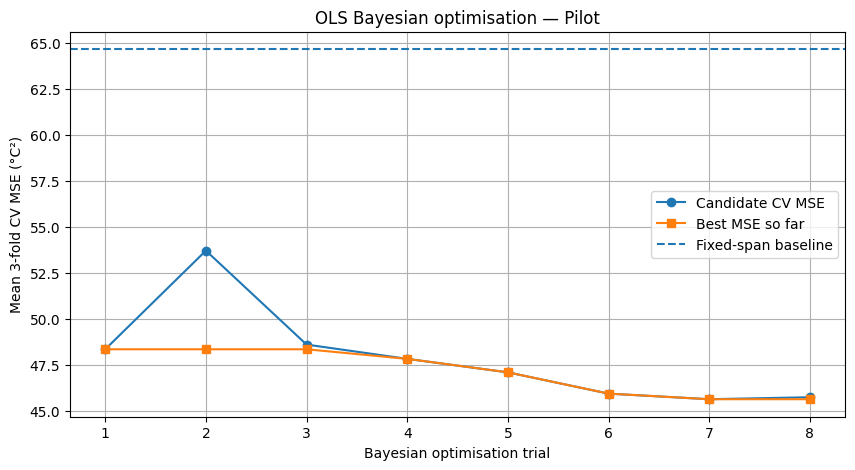

In [29]:

# STEP 6.3D — Visualise Bayesian search progress

import matplotlib.pyplot as plt

history = pd.DataFrame(trial_records)

history["best_so_far"] = (
    history["mean_cv_mse"].cummin()
)

plt.figure(figsize=(10, 5))

plt.plot(
    history["trial"],
    history["mean_cv_mse"],
    "o-",
    label="Candidate CV MSE"
)

plt.plot(
    history["trial"],
    history["best_so_far"],
    "s-",
    label="Best MSE so far"
)

plt.axhline(
    baseline_mse,
    linestyle="--",
    label="Fixed-span baseline"
)

plt.xlabel("Bayesian optimisation trial")
plt.ylabel("Mean 3-fold CV MSE (°C²)")
plt.title("OLS Bayesian optimisation — Pilot")
plt.legend()
plt.grid(True)
plt.show()


### 4.8.2 Review and Expansion of Search Intervals (Step 6.3B)

Inspection of the initial optimisation results revealed that three of the four selected spans reached their respective upper search limits. This suggested that the initial search intervals might constrain the exploration of longer temporal-memory representations.

Consequently, the search space was expanded and reparameterised using the first span and three positive differences between consecutive spans:

$$
\begin{aligned}
s_1 &= a \\
s_2 &= a+d_2 \\
s_3 &= a+d_2+d_3 \\
s_4 &= a+d_2+d_3+d_4
\end{aligned}
$$

This parameterisation guaranteed strictly increasing span values while permitting a wider range of smoothing timescales.

The expanded intervals were 5–100 for the first span, 1–400 for the second-span increment, 1–1,500 for the third-span increment and 1–6,000 for the fourth-span increment.

The original eight evaluated configurations were reused by supplying their recorded objective values to the newly parameterised Gaussian-process optimiser. Twenty additional configurations were then evaluated, producing 28 evaluations in total. Results were checkpointed after each completed trial.

In [30]:

# STEP 6.3B.1 — Expanded Bayesian search setup

import os
import time
import numpy as np
import pandas as pd

from skopt import Optimizer
from skopt.space import Integer

PILOT_PATH = "bayesian_ols_pilot_trials.csv"
EXPANDED_PATH = "bayesian_ols_expanded_trials.csv"

# New search space: first span + three positive gaps
expanded_space = [
    Integer(5, 100, name="s1"),
    Integer(1, 400, name="gap_2"),
    Integer(1, 1500, name="gap_3"),
    Integer(1, 6000, name="gap_4")
]

def decode_spans(parameters):
    """Convert first span and gaps into four ordered spans."""
    a, d2, d3, d4 = map(int, parameters)

    return [
        a,
        a + d2,
        a + d2 + d3,
        a + d2 + d3 + d4
    ]


def encode_spans(spans):
    """Convert four ordered spans into the new search space."""
    a, b, c, d = map(int, spans)

    if not a < b < c < d:
        raise ValueError("Spans must be strictly increasing")

    return [a, b-a, c-b, d-c]


# Restore the eight previous Bayesian trials
if os.path.exists(PILOT_PATH):
    pilot_df = pd.read_csv(PILOT_PATH)
elif "trial_records" in globals() and len(trial_records) > 0:
    pilot_df = pd.DataFrame(trial_records)
    pilot_df.to_csv(PILOT_PATH, index=False)
else:
    raise FileNotFoundError(
        "Previous pilot trials not found. "
        "Restore bayesian_ols_pilot_trials.csv first."
    )

assert len(pilot_df) == 8

# Confirm all old trials fit in the expanded space
for _, row in pilot_df.iterrows():
    old_spans = [
        int(row["s1"]), int(row["s2"]),
        int(row["s3"]), int(row["s4"])
    ]

    params = encode_spans(old_spans)

    assert all(
        dimension.low <= value <= dimension.high
        for dimension, value in zip(expanded_space, params)
    )

print("PASS: All eight previous trials are reusable")

print("\nPrevious best configuration:")
best_old = pilot_df.loc[
    pilot_df["mean_cv_mse"].idxmin()
]

print("Spans:", [
    int(best_old[f"s{i}"]) for i in range(1, 5)
])
print("CV MSE:", best_old["mean_cv_mse"])


PASS: All eight previous trials are reusable

Previous best configuration:
Spans: [30, 150, 652, 3000]
CV MSE: 45.64670386344701


In [31]:

# STEP 6.3B.2 — Continue Bayesian optimisation

N_ADDITIONAL_TRIALS = 20

# Load any previously completed expanded trials
if os.path.exists(EXPANDED_PATH):
    expanded_df = pd.read_csv(EXPANDED_PATH)
else:
    expanded_df = pd.DataFrame(columns=pilot_df.columns)

# Reconstruct the optimiser from recorded results
optimizer = Optimizer(
    dimensions=expanded_space,
    base_estimator="GP",
    n_initial_points=10,
    acq_func="EI",
    random_state=42
)

existing_history = pd.concat(
    [pilot_df, expanded_df],
    ignore_index=True
)

# Reuse all completed evaluations
for _, row in existing_history.iterrows():

    spans = [
        int(row["s1"]), int(row["s2"]),
        int(row["s3"]), int(row["s4"])
    ]

    parameters = encode_spans(spans)

    optimizer.tell(
        parameters,
        float(row["mean_cv_mse"])
    )

print("Existing evaluations:", len(existing_history))

remaining = max(
    0,
    N_ADDITIONAL_TRIALS - len(expanded_df)
)

print("Additional evaluations remaining:", remaining)

# Search for new configurations
for _ in range(remaining):

    parameters = optimizer.ask()
    spans = decode_spans(parameters)

    start = time.perf_counter()

    mean_mse, fold_scores = evaluate_ols_cv(spans)

    duration = time.perf_counter() - start

    optimizer.tell(parameters, mean_mse)

    record = {
        "trial": len(pilot_df) + len(expanded_df) + 1,
        "s1": spans[0],
        "s2": spans[1],
        "s3": spans[2],
        "s4": spans[3],
        "fold1_mse": fold_scores[0],
        "fold2_mse": fold_scores[1],
        "fold3_mse": fold_scores[2],
        "mean_cv_mse": mean_mse,
        "runtime_s": duration
    }

    expanded_df = pd.concat(
        [expanded_df, pd.DataFrame([record])],
        ignore_index=True
    )

    # Checkpoint after every completed trial
    expanded_df.to_csv(
        EXPANDED_PATH,
        index=False
    )

    print(
        f"Trial {record['trial']}: "
        f"spans={spans}, "
        f"MSE={mean_mse:.4f}, "
        f"time={duration:.1f}s",
        flush=True
    )

print("\nPASS: Expanded Bayesian pilot completed")

# Combine original and new results
all_trials = pd.concat(
    [pilot_df, expanded_df],
    ignore_index=True
)

best_result = all_trials.loc[
    all_trials["mean_cv_mse"].idxmin()
]

best_spans = [
    int(best_result[f"s{i}"]) for i in range(1, 5)
]

print("\nBest spans:", best_spans)
print(
    "Best 3-fold CV MSE:",
    round(float(best_result["mean_cv_mse"]), 4)
)

display(
    all_trials.sort_values("mean_cv_mse")
    .head(10)
    .round(4)
)


/tmp/ipykernel_1091/1092856163.py:20: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  existing_history = pd.concat(


Existing evaluations: 8
Additional evaluations remaining: 20
Trial 9: spans=[81, 155, 1325, 4907], MSE=45.5580, time=13.5s


/tmp/ipykernel_1091/1092856163.py:76: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  expanded_df = pd.concat(


Trial 10: spans=[47, 88, 777, 2780], MSE=45.8290, time=8.6s
Trial 11: spans=[100, 352, 1852, 4548], MSE=46.1153, time=9.1s
Trial 12: spans=[97, 399, 1899, 6123], MSE=46.8413, time=12.6s
Trial 13: spans=[100, 472, 1120, 4932], MSE=45.7870, time=11.5s
Trial 14: spans=[89, 265, 622, 3829], MSE=45.1303, time=8.4s
Trial 15: spans=[82, 349, 423, 4431], MSE=45.3567, time=9.4s
Trial 16: spans=[100, 101, 102, 6102], MSE=48.5818, time=9.1s
Trial 17: spans=[9, 307, 593, 4304], MSE=45.4092, time=9.2s
Trial 18: spans=[100, 500, 2000, 2955], MSE=46.1049, time=8.7s
Trial 19: spans=[85, 86, 1586, 7586], MSE=47.3646, time=9.2s
Trial 20: spans=[97, 311, 312, 3754], MSE=45.3615, time=9.2s
Trial 21: spans=[100, 101, 1601, 1602], MSE=46.7346, time=8.2s
Trial 22: spans=[69, 230, 1080, 6224], MSE=46.2137, time=9.3s
Trial 23: spans=[100, 500, 1693, 3704], MSE=45.9789, time=10.3s
Trial 24: spans=[100, 499, 1005, 4037], MSE=45.4982, time=9.2s
Trial 25: spans=[100, 101, 315, 3599], MSE=45.6623, time=8.3s
Trial 2

,trial,s1,s2,s3,s4,fold1_mse,fold2_mse,fold3_mse,mean_cv_mse,runtime_s
13,14,89,265,622,3829,64.9351,36.5415,33.9143,45.1303,8.4410
26,27,31,431,432,4117,65.0201,36.7019,34.2262,45.3161,9.0610
14,15,82,349,423,4431,65.1270,36.5760,34.3670,45.3567,9.4389
19,20,97,311,312,3754,65.3140,36.9087,33.8619,45.3615,9.1647
16,17,9,307,593,4304,65.3289,36.6188,34.2800,45.4092,9.2402
23,24,100,499,1005,4037,64.8505,37.0755,34.5687,45.4982,9.2039
8,9,81,155,1325,4907,64.7220,37.1666,34.7855,45.5580,13.4889
27,28,12,374,1026,4377,65.1186,37.1409,34.5028,45.5874,9.4951
6,7,30,150,652,3000,65.8372,37.5159,33.5870,45.6467,9.1906
24,25,100,101,315,3599,65.5293,37.6367,33.8211,45.6623,8.2776


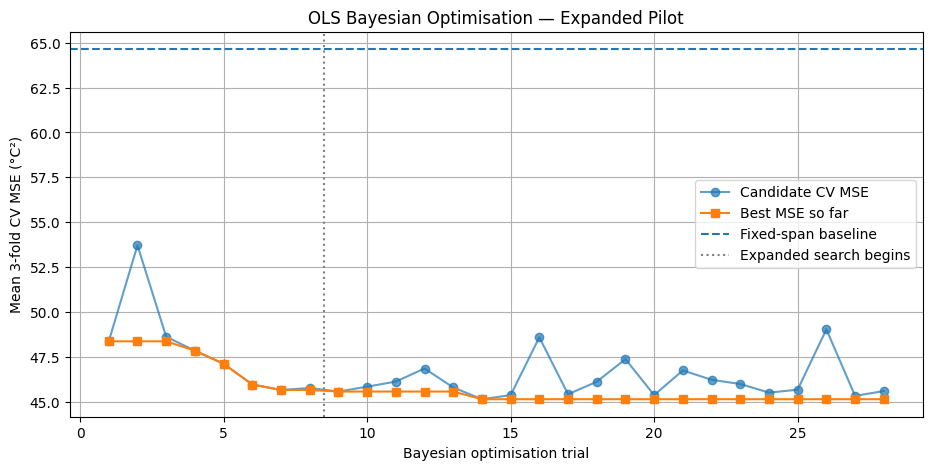

Original pilot best MSE: 45.6467
Expanded search best MSE: 45.1303
Total evaluations: 28


In [32]:

# STEP 6.3B.3 — Compare original and expanded search

import matplotlib.pyplot as plt

history = all_trials.copy()

history["best_so_far"] = (
    history["mean_cv_mse"].cummin()
)

plt.figure(figsize=(11, 5))

plt.plot(
    history["trial"],
    history["mean_cv_mse"],
    "o-",
    label="Candidate CV MSE",
    alpha=0.7
)

plt.plot(
    history["trial"],
    history["best_so_far"],
    "s-",
    label="Best MSE so far"
)

# Original manually selected span configuration
plt.axhline(
    64.6399,
    linestyle="--",
    label="Fixed-span baseline"
)

# Mark where the expanded search begins
plt.axvline(
    8.5,
    linestyle=":",
    color="grey",
    label="Expanded search begins"
)

plt.xlabel("Bayesian optimisation trial")
plt.ylabel("Mean 3-fold CV MSE (°C²)")
plt.title("OLS Bayesian Optimisation — Expanded Pilot")
plt.legend()
plt.grid(True)
plt.show()

print("Original pilot best MSE:",
      round(pilot_df["mean_cv_mse"].min(), 4))

print("Expanded search best MSE:",
      round(history["mean_cv_mse"].min(), 4))

print("Total evaluations:", len(history))


### 4.8.3 Results of the Expanded Optimisation

The expanded search identified its best configuration at Trial 14.

| Parameter | Initial best | Expanded best |
|:----------|-------------:|--------------:|
| Span 1 | 30 | 89 |
| Span 2 | 150 | 265 |
| Span 3 | 652 | 622 |
| Span 4 | 3,000 | 3,829 |
| Mean CV MSE (°C²) | 45.6467 | **45.1303** |

The expanded configuration produced validation MSE values of 64.9351, 36.5416 and 33.9143 °C² across the three folds, respectively.

The expanded search achieved an additional **1.13% reduction** relative to the initial Bayesian optimum, corresponding to a total **30.18% reduction** relative to the original fixed-span reference.

The optimisation-history plot demonstrated substantial improvements during the initial search, followed by smaller improvements during the expanded search. This suggests diminishing returns within the reduced-data experimental setup, although the limited number of evaluations does not establish global convergence.

### 4.8.4 Interpretation and Limitations

The experiments demonstrated that systematic Bayesian optimisation could identify EWMA/EWMS span configurations that substantially improved OLS cross-validation performance relative to manually selected demonstration values.

The expanded search also demonstrated the value of reviewing optimisation boundaries rather than assuming the first selected configuration was optimal.

However, these results remain preliminary. The optimisation was conducted using a reduced set of observations, rather than the complete development dataset. Consequently, the selected spans and performance metrics may differ when full-data optimisation is performed.

Furthermore, improvements in average cross-validation MSE do not establish that the previously identified extreme OLS prediction at the start of profile 65 has been resolved. A separate matched diagnostic would be required to investigate that question.

The 14 final test profiles remained excluded from all optimisation procedures.

### 4.8.5 Conclusion

Steps 6.3A and 6.3B successfully implemented, verified and expanded the Bayesian optimisation framework for OLS-based permanent-magnet temperature estimation.

The initial eight-trial search reduced average cross-validation MSE from 64.6399 to 45.6467 °C². Extending the search to 28 total evaluations further reduced the MSE to 45.1303 °C².

The completed experiments establish a functioning Bayesian optimisation procedure and provide preliminary evidence that optimised temporal-feature spans can improve predictive performance.

The next stage will extend this approach to the remaining regression algorithms before conducting the full-data benchmark.